<a href="https://colab.research.google.com/github/bilgeerol/bim448-sentiment/blob/main/notebooks/06_karsilastirma.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 06 – Karşılaştırma
**Sahibi:** Bilge · **Amaç:** Yedi deneyin sonuçlarını yan yana koymak: karşılaştırma tablosu ve üç karşılaştırma grafiği.
**Girdi:** `results/tables/ozet_metrikler.csv`, `results/tables/*_hatalar.csv`, `results/tables/*_metrikler.csv` (Zehra'nın 05 notebook'unun çıktıları)
**Çıktı:** `results/tables/karsilastirma_tablosu.csv`, `results/figures/karsilastirma_macro_f1.png`, `karsilastirma_sinif_hatalari.png`, `karsilastirma_sinif_f1.png`

In [1]:
# 0. KURULUM HÜCRESİ — her oturumda ilk bu çalıştırılır
from google.colab import userdata, drive
import os

drive.mount('/content/drive')

TOKEN = userdata.get('GITHUB_TOKEN')
REPO_OWNER = "bilgeerol"
REPO = "bim448-sentiment"
REPO_DIR = f"/content/{REPO}"

if not os.path.exists(REPO_DIR):
    !git clone https://{TOKEN}@github.com/{REPO_OWNER}/{REPO}.git {REPO_DIR}
%cd {REPO_DIR}
!git pull
!git config user.name "Bilge Erol"
!git config user.email "bilgeerol02@gmail.com"

Mounted at /content/drive
Cloning into '/content/bim448-sentiment'...
remote: Enumerating objects: 337, done.
remote: Counting objects: 100% (337/337), done.
remote: Compressing objects: 100% (240/240), done.
remote: Total 337 (delta 193), reused 215 (delta 89), pack-reused 0 (from 0)
Receiving objects: 100% (337/337), 5.52 MiB | 14.03 MiB/s, done.
Resolving deltas: 100% (193/193), done.
/content/bim448-sentiment
Already up to date.


In [2]:
# 1. Ortak ayarlar: yöntemler, renkler ve Zehra'nın değerlendirme sonuçlarını oku
import os
import pandas as pd
import matplotlib.pyplot as plt

TABLO_DIR = "results/tables"
SEKIL_DIR = "results/figures"

# (evaluate.py'deki model adı, dil, rapordaki yöntem adı, dosya ön eki)
KAYITLAR = [
    ("VADER",                  "EN", "VADER",                  "vader_en"),
    ("VADER (doğrudan)",       "TR", "VADER (doğrudan)",       "vader_dogrudan_tr"),
    ("VADER (çeviri sonrası)", "TR", "VADER (çeviri sonrası)", "vader_cevirili_tr"),
    ("BERT (RoBERTa)",         "EN", "BERT",                   "bert_en"),
    ("BERT (BERTurk)",         "TR", "BERT",                   "bert_tr"),
    ("LLM (gpt-oss-120b)",     "EN", "LLM",                    "llm_en"),
    ("LLM (gpt-oss-120b)",     "TR", "LLM",                    "llm_tr"),
]
YONTEMLER = ["VADER", "VADER (doğrudan)", "VADER (çeviri sonrası)", "BERT", "LLM"]
# Her yöntemin rengi bütün grafiklerde (ve video slaytlarında) aynı kalır
RENK = {"VADER": "#2a78d6", "VADER (doğrudan)": "#eb6834", "VADER (çeviri sonrası)": "#1baf7a",
        "BERT": "#eda100", "LLM": "#e87ba4"}
SINIFLAR = ["Negatif", "Nötr", "Pozitif"]
DIL_AD = {"EN": "İngilizce", "TR": "Türkçe"}

def virgul(x, basamak=3):
    return f"{x:.{basamak}f}".replace(".", ",")

ozet_yol = os.path.join(TABLO_DIR, "ozet_metrikler.csv")
if not os.path.exists(ozet_yol):
    raise SystemExit("⏳ ozet_metrikler.csv henüz yok: Zehra'nın 'sonuçlar hazır' mesajını bekle, sonra kurulum hücresini ve bu hücreyi yeniden çalıştır.")
ozet = pd.read_csv(ozet_yol, encoding="utf-8")

satirlar = []
for model, dil, yontem, onek in KAYITLAR:
    o = ozet[(ozet["model"] == model) & (ozet["dil"] == dil)]
    hata_yol = os.path.join(TABLO_DIR, f"{onek}_hatalar.csv")
    metrik_yol = os.path.join(TABLO_DIR, f"{onek}_metrikler.csv")
    if o.empty or not os.path.exists(hata_yol) or not os.path.exists(metrik_yol):
        print(f"⚠️ EKSİK: {model} – {dil} (Zehra'nın değerlendirmesi henüz yok)")
        continue
    satirlar.append({"yontem": yontem, "dil": dil, "accuracy": o["accuracy"].iloc[0],
                     "macro_f1": o["macro_f1"].iloc[0],
                     "hatalar": pd.read_csv(hata_yol, encoding="utf-8").set_index("Sınıf"),
                     "metrikler": pd.read_csv(metrik_yol, encoding="utf-8").set_index("Sınıf")})
print(f"✅ {len(satirlar)} / 7 deneyin sonuçları okundu")

✅ 7 / 7 deneyin sonuçları okundu


In [3]:
# 2. Karşılaştırma tablosu (results/tables/karsilastirma_tablosu.csv)
tablo = pd.DataFrame(index=YONTEMLER,
                     columns=["EN Doğruluk", "EN Makro-F1", "TR Doğruluk", "TR Makro-F1"], dtype=float)
for s in satirlar:
    tablo.loc[s["yontem"], f"{s['dil']} Doğruluk"] = round(s["accuracy"], 3)
    tablo.loc[s["yontem"], f"{s['dil']} Makro-F1"] = round(s["macro_f1"], 3)
tablo.index.name = "Yöntem"
tablo.to_csv(os.path.join(TABLO_DIR, "karsilastirma_tablosu.csv"), encoding="utf-8")
print("✅ karsilastirma_tablosu.csv kaydedildi (boş hücre = o dilde uygulanmadı)")
display(tablo)

✅ karsilastirma_tablosu.csv kaydedildi (boş hücre = o dilde uygulanmadı)


,EN Doğruluk,EN Makro-F1,TR Doğruluk,TR Makro-F1
Yöntem,,,,
VADER,0.509,0.463,NaN,NaN
VADER (doğrudan),NaN,NaN,0.351,0.230
VADER (çeviri sonrası),NaN,NaN,0.546,0.514
BERT,0.796,0.796,0.830,0.829
LLM,0.734,0.717,0.748,0.726


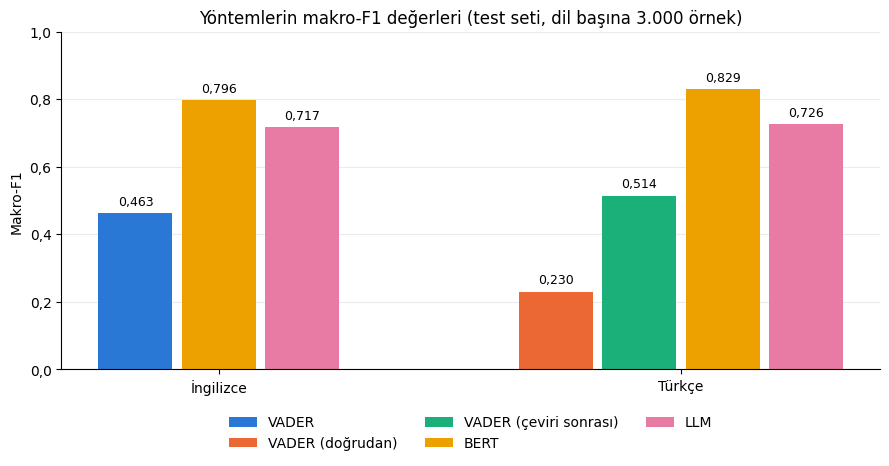

In [4]:
# 3. Şekil 1: yöntem başına makro-F1, İngilizce ve Türkçe yan yana
fig, ax = plt.subplots(figsize=(9, 4.8))
genislik = 0.16
x_merkez = {"EN": 0, "TR": 1}
etiket_kondu = set()
for dil in ["EN", "TR"]:
    dil_satir = [s for s in satirlar if s["dil"] == dil]
    dil_satir.sort(key=lambda s: YONTEMLER.index(s["yontem"]))
    n = len(dil_satir)
    for i, s in enumerate(dil_satir):
        x = x_merkez[dil] + (i - (n - 1) / 2) * (genislik + 0.02)
        ax.bar(x, s["macro_f1"], width=genislik, color=RENK[s["yontem"]],
               label=None if s["yontem"] in etiket_kondu else s["yontem"])
        etiket_kondu.add(s["yontem"])
        ax.text(x, s["macro_f1"] + 0.015, virgul(s["macro_f1"]), ha="center", va="bottom", fontsize=9)
ax.set_xticks([0, 1], [DIL_AD["EN"], DIL_AD["TR"]])
ax.set_ylim(0, 1)
ax.yaxis.set_major_formatter(lambda v, _: virgul(v, 1))
ax.set_ylabel("Makro-F1")
ax.set_title("Yöntemlerin makro-F1 değerleri (test seti, dil başına 3.000 örnek)")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", alpha=0.25)
ax.set_axisbelow(True)
tutamac, ad = ax.get_legend_handles_labels()
sira = [ad.index(y) for y in YONTEMLER if y in ad]
ax.legend([tutamac[i] for i in sira], [ad[i] for i in sira], frameon=False, ncol=3,
          loc="upper center", bbox_to_anchor=(0.5, -0.1))
fig.tight_layout()
fig.savefig(os.path.join(SEKIL_DIR, "karsilastirma_macro_f1.png"), dpi=300, bbox_inches="tight")
plt.show()

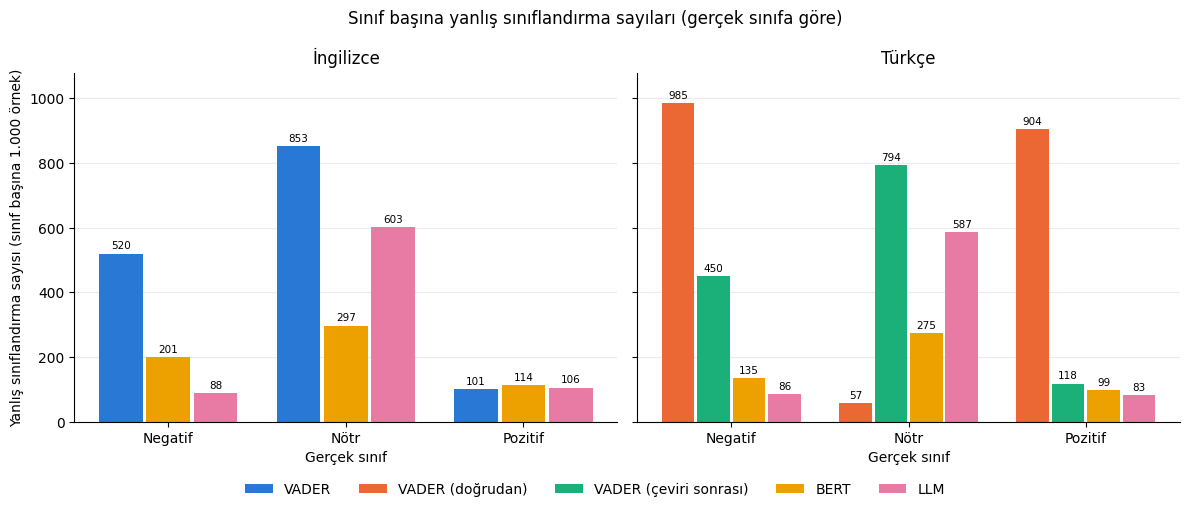

In [5]:
# 4. Şekil 2: sınıf başına hata sayısı (gerçek sınıfa göre), İngilizce ve Türkçe iki panel
fig, eksenler = plt.subplots(1, 2, figsize=(12, 4.8), sharey=True)
for ax, dil in zip(eksenler, ["EN", "TR"]):
    dil_satir = sorted([s for s in satirlar if s["dil"] == dil], key=lambda s: YONTEMLER.index(s["yontem"]))
    n = len(dil_satir)
    genislik = 0.8 / max(n, 1)
    for i, s in enumerate(dil_satir):
        degerler = [int(s["hatalar"].loc[sinif, "Gerçek sınıfa göre hata"]) for sinif in SINIFLAR]
        xler = [j + (i - (n - 1) / 2) * genislik for j in range(len(SINIFLAR))]
        ax.bar(xler, degerler, width=genislik * 0.92, color=RENK[s["yontem"]], label=s["yontem"])
        for x, d in zip(xler, degerler):
            ax.text(x, d + 8, f"{d:,}".replace(",", "."), ha="center", va="bottom", fontsize=7.5)
    ax.set_xticks(range(len(SINIFLAR)), SINIFLAR)
    ax.set_title(DIL_AD[dil])
    ax.set_xlabel("Gerçek sınıf")
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", alpha=0.25)
    ax.set_axisbelow(True)
eksenler[0].set_ylim(0, 1080)
eksenler[0].set_ylabel("Yanlış sınıflandırma sayısı (sınıf başına 1.000 örnek)")
fig.suptitle("Sınıf başına yanlış sınıflandırma sayıları (gerçek sınıfa göre)")
tum = {}
for ax in eksenler:
    for t, a in zip(*ax.get_legend_handles_labels()):
        tum.setdefault(a, t)
fig.legend([tum[y] for y in YONTEMLER if y in tum], [y for y in YONTEMLER if y in tum],
           frameon=False, ncol=5, loc="lower center", bbox_to_anchor=(0.5, -0.06))
fig.tight_layout()
fig.savefig(os.path.join(SEKIL_DIR, "karsilastirma_sinif_hatalari.png"), dpi=300, bbox_inches="tight")
plt.show()

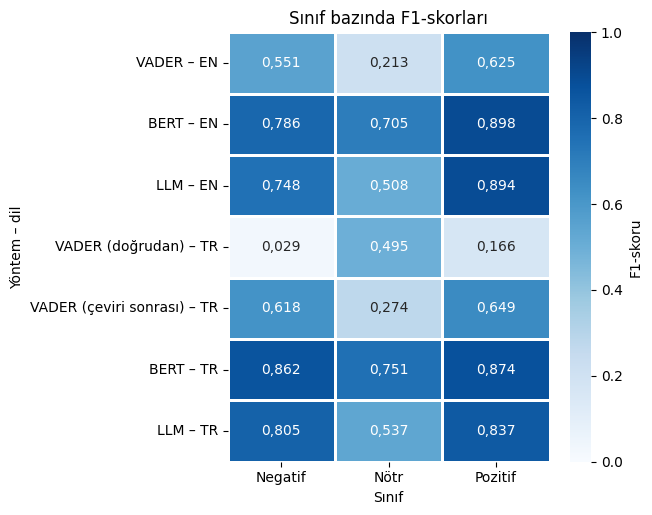

In [6]:
# 5. Şekil 3: sınıf bazlı F1 ısı haritası (satır: yöntem – dil, sütun: sınıf)
import seaborn as sns
isi = pd.DataFrame({f"{s['yontem']} – {s['dil']}": [s["metrikler"].loc[sinif, "F1-skoru"] for sinif in SINIFLAR]
                    for s in sorted(satirlar, key=lambda s: (s["dil"], YONTEMLER.index(s["yontem"])))},
                   index=SINIFLAR).T
fig, ax = plt.subplots(figsize=(6.5, 0.55 * len(isi) + 1.4))
sns.heatmap(isi, annot=isi.map(virgul), fmt="", cmap="Blues", vmin=0, vmax=1, linewidths=2,
            linecolor="white", cbar_kws={"label": "F1-skoru"}, ax=ax, annot_kws={"size": 10})
ax.set_xlabel("Sınıf")
ax.set_ylabel("Yöntem – dil")
ax.tick_params(axis="y", rotation=0)
ax.set_title("Sınıf bazında F1-skorları")
fig.tight_layout()
fig.savefig(os.path.join(SEKIL_DIR, "karsilastirma_sinif_f1.png"), dpi=300, bbox_inches="tight")
plt.show()

In [7]:
# 6. B7 çıktılarını GitHub'a gönder (yalnızca bu 4 dosya)
!git add results/tables/karsilastirma_tablosu.csv results/figures/karsilastirma_macro_f1.png results/figures/karsilastirma_sinif_hatalari.png results/figures/karsilastirma_sinif_f1.png
!git commit -m "[Bilge] Karşılaştırma tablosu ve 3 grafik eklendi (B7)"
!git pull --rebase
!git push

[main 0e1f82d] [Bilge] Karşılaştırma tablosu ve 3 grafik eklendi (B7)
 4 files changed, 6 insertions(+)
 create mode 100644 results/figures/karsilastirma_macro_f1.png
 create mode 100644 results/figures/karsilastirma_sinif_f1.png
 create mode 100644 results/figures/karsilastirma_sinif_hatalari.png
 create mode 100644 results/tables/karsilastirma_tablosu.csv
Current branch main is up to date.
Enumerating objects: 13, done.
Counting objects: 100% (13/13), done.
Delta compression using up to 2 threads
Compressing objects: 100% (9/9), done.
Writing objects: 100% (9/9), 363.78 KiB | 12.54 MiB/s, done.
Total 9 (delta 3), reused 0 (delta 0), pack-reused 0
remote: Resolving deltas: 100% (3/3), completed with 3 local objects.
To https://github.com/bilgeerol/bim448-sentiment.git
   d86c8a1..0e1f82d  main -> main
